# 2. Veri Ön İşleme ve Özellik Mühendisliği (NASA C-MAPSS — FD001)

Bu aşamada `01_veriseti_tanitimi` bulgularına dayanarak veri temizleme, hedef değişken (`RUL`) oluşturma, motor bazlı zaman serisi özellik mühendisliği(feature engineering), ölçekleme ve özellik seçimi/önem analizi adımları gerçekleştirilmektedir. Tüm öğrenme ve eşik/ölçek parametreleri veri sızıntısını önlemek amacıyla yalnızca eğitim seti (`train_FD001`) üzerinden belirlenmektedir.

## 2.1 Eksik/Tutarsız Veri Kontrolü ve Sabit Kanalların Silinmesi
Bu adımda veri setinin bütünlüğü (eksik ve mükerrer kayıtlar) doğrulanmakta, sabit (`T2`) ve aktif (`T24`) bir kanalın döngü boyunca davranışı görselleştirilmekte ve yalnızca eğitim seti (`train_df`) bulgularına dayanarak tek değerli (`nunique <= 1`) sabit kanallar eğitim ve test setlerinden çıkarılmaktadır.

Train eksik değer sayısı: 0
Test eksik değer sayısı : 0
Train mükerrer (unit, cycle): 0
Test mükerrer (unit, cycle) : 0


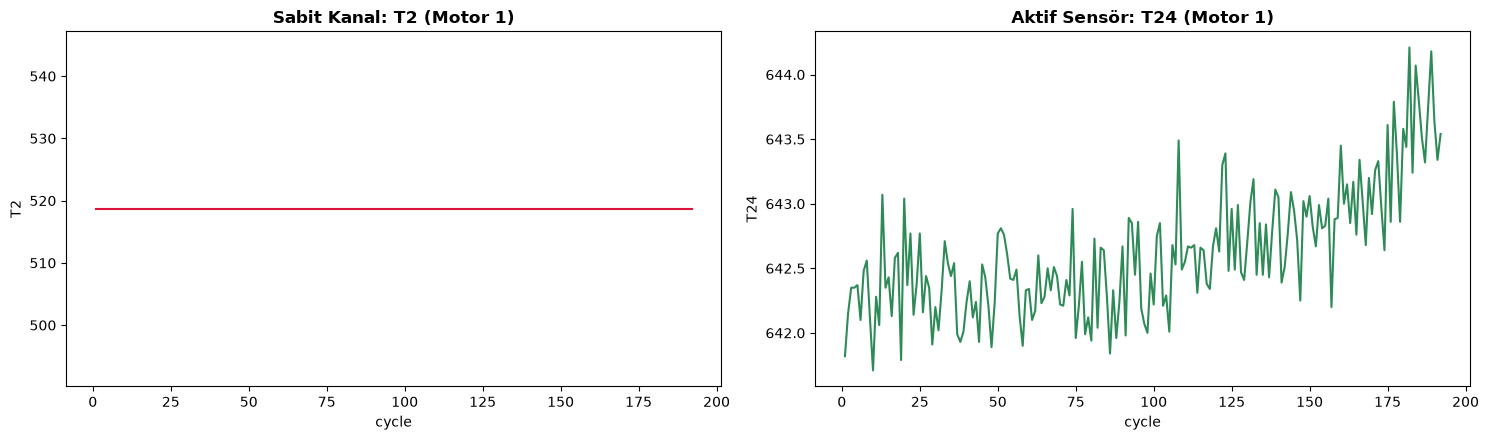


Çıkarılan sabit sütunlar: ['op_set3', 'T2', 'P2', 'epr', 'farB', 'Nf_dmd', 'PCNfR_dmd']
Çıkarılan sütun sayısı: 7
train_clean şekli: (20631, 19)
test_clean şekli : (13096, 19)


In [100]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

index_cols = ["unit", "cycle"]
op_cols = ["op_set1", "op_set2", "op_set3"]
sensor_cols = [
    "T2",
    "T24",
    "T30",
    "T50",
    "P2",
    "P15",
    "P30",
    "Nf",
    "Nc",
    "epr",
    "Ps30",
    "phi",
    "NRf",
    "NRc",
    "BPR",
    "farB",
    "htBleed",
    "Nf_dmd",
    "PCNfR_dmd",
    "W31",
    "W32",
]
all_cols = index_cols + op_cols + sensor_cols

data_dir = next(
    (
        p
        for p in [Path("data"), Path("../data")]
        if (p / "train_FD001.txt").exists()
    ),
    None,
)
if data_dir is None:
  raise FileNotFoundError(
      f"train_FD001.txt bulunamadı. Mevcut dizin: {Path.cwd()}"
  )

train_df = pd.read_csv(
    data_dir / "train_FD001.txt", sep=r"\s+", header=None, names=all_cols
)
test_df = pd.read_csv(
    data_dir / "test_FD001.txt", sep=r"\s+", header=None, names=all_cols
)

# 1) Eksik ve mükerrer kayıt kontrolü
print("Train eksik değer sayısı:", int(train_df.isna().sum().sum()))
print("Test eksik değer sayısı :", int(test_df.isna().sum().sum()))
print(
    "Train mükerrer (unit, cycle):",
    int(train_df.duplicated(subset=["unit", "cycle"]).sum()),
)
print(
    "Test mükerrer (unit, cycle) :",
    int(test_df.duplicated(subset=["unit", "cycle"]).sum()),
)

# 2) Sabit (T2) ve aktif (T24) sensör karşılaştırması (Motor 1)
sample_unit = 1
unit_df = train_df[train_df["unit"] == sample_unit]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.lineplot(data=unit_df, x="cycle", y="T2", ax=ax[0], color="crimson")
ax[0].set_title(f"Sabit Kanal: T2 (Motor {sample_unit})", fontweight="bold")

sns.lineplot(data=unit_df, x="cycle", y="T24", ax=ax[1], color="seagreen")
ax[1].set_title(f"Aktif Sensör: T24 (Motor {sample_unit})", fontweight="bold")

plt.tight_layout()
plt.show()

# 3) Sabit sütunları yalnızca train_df üzerinden belirle ve her iki setten çıkar
constant_cols = [
    col for col in train_df.columns if train_df[col].nunique() <= 1
]
train_clean = train_df.drop(columns=constant_cols).copy()
test_clean = test_df.drop(columns=constant_cols).copy()

print("\nÇıkarılan sabit sütunlar:", constant_cols)
print("Çıkarılan sütun sayısı:", len(constant_cols))
print("train_clean şekli:", train_clean.shape)
print("test_clean şekli :", test_clean.shape)

### Hedef Değişkenlerin Oluşturulması (`RUL_linear` ve `RUL_capped125`)
Eğitim setindeki her motor (`unit`) arıza döngüsüne kadar çalıştığından, kalan kullanım ömrü (`RUL_linear = max_cycle - cycle`) doğrudan hesaplanabilmektedir. Erken sağlıklı döngülerdeki yatay davranışı dengelemek ve bozulmaya yakın kritik döneme odaklanmak amacıyla `125` döngü üst sınırlı `RUL_capped125` hedefi de eklenmektedir. Test setinde gerçek RUL değerleri ayrı dosyada tutulduğundan bu adım yalnızca eğitim setine uygulanmaktadır.

In [101]:
RUL_CAP = 125

max_cycle_train = train_clean.groupby("unit")["cycle"].transform("max")
train_clean["RUL_linear"] = max_cycle_train - train_clean["cycle"]
train_clean["RUL_capped125"] = train_clean["RUL_linear"].clip(upper=RUL_CAP)

print(train_clean[["unit", "cycle", "RUL_linear", "RUL_capped125"]].head(10))
print("\nRUL_capped125 özet istatistikleri:")
print(train_clean["RUL_capped125"].describe().round(2))

   unit  cycle  RUL_linear  RUL_capped125
0     1      1         191            125
1     1      2         190            125
2     1      3         189            125
3     1      4         188            125
4     1      5         187            125
5     1      6         186            125
6     1      7         185            125
7     1      8         184            125
8     1      9         183            125
9     1     10         182            125

RUL_capped125 özet istatistikleri:
count    20631.00
mean        86.83
std         41.67
min          0.00
25%         51.00
50%        103.00
75%        125.00
max        125.00
Name: RUL_capped125, dtype: float64


In [102]:
print("=== TEMİZLENMİŞ EĞİTİM VERİ SETİ VERİ TİPLERİ VE BELLEK ÖZETİ ===")
train_clean.info()

=== TEMİZLENMİŞ EĞİTİM VERİ SETİ VERİ TİPLERİ VE BELLEK ÖZETİ ===
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   unit           20631 non-null  int64  
 1   cycle          20631 non-null  int64  
 2   op_set1        20631 non-null  float64
 3   op_set2        20631 non-null  float64
 4   T24            20631 non-null  float64
 5   T30            20631 non-null  float64
 6   T50            20631 non-null  float64
 7   P15            20631 non-null  float64
 8   P30            20631 non-null  float64
 9   Nf             20631 non-null  float64
 10  Nc             20631 non-null  float64
 11  Ps30           20631 non-null  float64
 12  phi            20631 non-null  float64
 13  NRf            20631 non-null  float64
 14  NRc            20631 non-null  float64
 15  BPR            20631 non-null  float64
 16  htBleed        20631 non-null  int64  


## 2.2 Zaman Serisi Özellik Mühendisliği (Feature Engineering)

Bu adımda doğrudan temizlenmiş eğitim (`train_clean`) ve test (`test_clean`) veri setlerindeki aktif çalışma ve sensör kanalları üzerinden motor (`unit`) bazlı zamansal özellikler türetilmektedir. Her motorun kendi döngü (`cycle`) sırası korunarak hesaplama yapılmakta; böylece motor geçişlerinde bir ünitenin son döngüsünün diğer ünitenin ilk döngüsüne karışması ve hedef değişken (`RUL_linear`, `RUL_capped125`) üzerinden özellik türetilerek veri sızıntısı oluşması engellenmektedir.

### Türetilen Özellikler (`window = 10`)
Aktif özellik sütunlarının her biri için aşağıdaki üç zamansal öznitelik oluşturulmaktadır:
* **Kayan Ortalama (`{col}_roll_mean_10`):** Kısa vadeli ölçüm dalgalanmalarını yumuşatarak sensördeki kademeli bozulma eğilimini daha belirgin hale getirmek amacıyla (`min_periods=1`).
* **Kayan Standart Sapma (`{col}_roll_std_10`):** Pencere içindeki yerel oynaklığı ve sinyal kararsızlığını ölçmek amacıyla (`min_periods=1`, ilk adımdaki `NaN` değerler `0.0` ile doldurulmaktadır).
* **Ardışık Fark (`{col}_diff`):** Ardışık döngüler arasındaki değişim miktarını ve bozulma hızını yakalamak amacıyla (`fillna(0.0)`).

In [103]:
import numpy as np
import pandas as pd

# Hedef ve kimlik sütunlarını özellik üretiminden hariç tutalım
exclude_cols = {"unit", "cycle", "RUL_linear", "RUL_capped125"}
base_feature_cols = [
    col for col in train_clean.columns if col not in exclude_cols
]

window = 10


def add_temporal_features(
    df: pd.DataFrame, feature_cols: list[str], win: int = 10
) -> pd.DataFrame:
  """Her motor (unit) için döngü (cycle) sırasına göre kayan pencere ve fark özellikleri üretir."""
  out_parts = []
  for _, grp in df.groupby("unit", sort=True):
    sub = grp.sort_values("cycle").copy()
    new_cols = {}

    for col in feature_cols:
      s = sub[col].astype(float)
      new_cols[f"{col}_roll_mean_{win}"] = s.rolling(
          window=win, min_periods=1
      ).mean()
      new_cols[f"{col}_roll_std_{win}"] = (
          s.rolling(window=win, min_periods=1).std().fillna(0.0)
      )
      new_cols[f"{col}_diff"] = s.diff().fillna(0.0)

    sub = pd.concat([sub, pd.DataFrame(new_cols, index=sub.index)], axis=1)
    out_parts.append(sub)

  return pd.concat(out_parts, ignore_index=True)


train_fe = add_temporal_features(train_clean, base_feature_cols, win=window)
test_fe = add_temporal_features(test_clean, base_feature_cols, win=window)

# Sonsuz (inf) veya eksik değer kontrolü
print("Temel özellik sayısı :", len(base_feature_cols))
print("train_fe şekli       :", train_fe.shape)
print("test_fe şekli        :", test_fe.shape)
print(
    "train_fe NaN / inf   :",
    int(train_fe.isna().sum().sum()),
    "/",
    int(np.isinf(train_fe.select_dtypes(include=np.number)).sum().sum()),
)
print(
    "test_fe NaN / inf    :",
    int(test_fe.isna().sum().sum()),
    "/",
    int(np.isinf(test_fe.select_dtypes(include=np.number)).sum().sum()),
)

Temel özellik sayısı : 17
train_fe şekli       : (20631, 72)
test_fe şekli        : (13096, 70)
train_fe NaN / inf   : 0 / 0
test_fe NaN / inf    : 0 / 0


### Türetilen Özelliklerin Tablo ve Grafik ile İncelenmesi (`unit = 1`)

Üretilen zamansal özelliklerin (`roll_mean_10`, `roll_std_10`, `diff`) motor bazında ve döngü sırasına göre doğru hesaplandığını somut olarak doğrulamak amacıyla örnek bir motor (`target_unit = 14`) ve seçili bir sensör (`sensor = "T24"`) üzerinden ilk döngülerin tablosu ile tüm ömür boyunca davranış grafiği incelenmektedir. Farklı bir motor veya sensör incelemek için `target_unit` ve `sensor` değişkenlerini değiştirmek yeterlidir.

,unit,cycle,T24,T24_roll_mean_10,T24_roll_std_10,T24_diff
0,1,1,641.82,641.820,0.000,0.00
1,1,2,642.15,641.985,0.233,0.33
2,1,3,642.35,642.107,0.268,0.20
3,1,4,642.35,642.168,0.250,0.00
4,1,5,642.37,642.208,0.235,0.02
5,1,6,642.10,642.190,0.215,-0.27
6,1,7,642.48,642.231,0.224,0.38
7,1,8,642.56,642.272,0.238,0.08
8,1,9,642.12,642.256,0.228,-0.44
9,1,10,641.71,642.201,0.276,-0.41


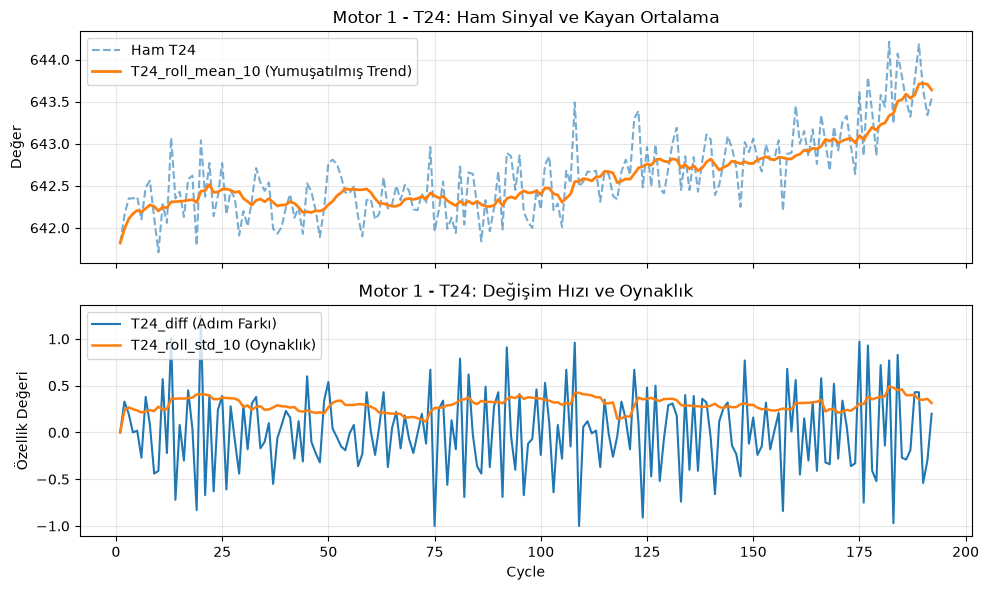

In [104]:
import matplotlib.pyplot as plt

# İncelemek istediğin motor ve sensörü buradan kolayca değiştirebilirsin
target_unit = 1
sensor = "T24"

cols_to_show = [
    "unit",
    "cycle",
    sensor,
    f"{sensor}_roll_mean_10",
    f"{sensor}_roll_std_10",
    f"{sensor}_diff",
]

# 1. İlk 12 döngü için tablo görünümü
sample_table = (
    train_fe[train_fe["unit"] == target_unit]
    .sort_values("cycle")[cols_to_show]
    .head(12)
    .round(3)
)
display(sample_table)  # Düz Python betiğinde çalışıyorsan print(sample_table) kullanabilirsin

# 2. Tüm döngüler boyunca görsel karşılaştırma
u_df = train_fe[train_fe["unit"] == target_unit].sort_values("cycle")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(
    u_df["cycle"],
    u_df[sensor],
    label=f"Ham {sensor}",
    alpha=0.6,
    linestyle="--",
)
axes[0].plot(
    u_df["cycle"],
    u_df[f"{sensor}_roll_mean_10"],
    label=f"{sensor}_roll_mean_10 (Yumuşatılmış Trend)",
    linewidth=2,
)
axes[0].set_title(f"Motor {target_unit} - {sensor}: Ham Sinyal ve Kayan Ortalama")
axes[0].set_ylabel("Değer")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    u_df["cycle"],
    u_df[f"{sensor}_diff"],
    label=f"{sensor}_diff (Adım Farkı)",
)
axes[1].plot(
    u_df["cycle"],
    u_df[f"{sensor}_roll_std_10"],
    label=f"{sensor}_roll_std_10 (Oynaklık)",
    linewidth=1.8,
)
axes[1].set_title(f"Motor {target_unit} - {sensor}: Değişim Hızı ve Oynaklık")
axes[1].set_xlabel("Cycle")
axes[1].set_ylabel("Özellik Değeri")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.3 Normalizasyon ve Standardizasyon (Ölçekleme)

Özellik mühendisliği adımı sonucunda elde edilen 17 temel kanal ve 51 türetilmiş zaman serisi özelliği olmak üzere toplam 68 öznitelik birbirinden farklı fiziksel birimlere ve sayısal genliklere sahiptir. Farklı ölçeklerdeki değişkenlerin bir arada bulunması; özellikle gradyan tabanlı, mesafe/kernel kullanan veya düzenlileştirme (*regularization*) uygulanan modellerde büyük genlikli sütunların öğrenme sürecini baskılamasına yol açabilmektedir. Bu nedenle `unit`, `cycle` ve hedef değişkenler (`RUL_linear`, `RUL_capped125`) ölçekleme kapsamı dışında bırakılarak yalnızca 68 girdi özelliği için ölçekleme yapısı tanımlanmıştır.

Bu çalışmada sütunların dağılım ve oynaklık davranışına göre iki farklı ölçekleyici birlikte yapılandırılmıştır (`ColumnTransformer`):
* **Standardizasyon (`StandardScaler`):** Temel aktif kanallar ile kayan ortalama (`roll_mean_10`) sütunlarında dağılım yapısını bozmadan ortalama ~0 ve standart sapma 1 olacak şekilde Z-skor dönüşümü planlanmıştır.
* **Dayanıklı Ölçekleme (`RobustScaler`):** Ardışık fark (`diff`) ve kayan standart sapma (`roll_std_10`) gibi anlık değişim ve yerel oynaklık barındıran sütunlarda ise medyan ve çeyrekler açıklığı (`IQR = Q3 - Q1`) esas alınarak ani dalgalanmaların ölçekleme katsayılarını bozması engellenmiştir.

Veri sızıntısını (*data leakage*) önlemek ve henüz tamamlanmamış olan özellik seçimi ile modelleme adımlarını etkilememek amacıyla ölçekleyici parametreleri yalnızca eğitim seti (`train_fe`) üzerinde öğrenilmiş (`fit`), test setine (`test_fe`) ise bu aşamada dönüşüm (`transform`) uygulanmamıştır. Nihai dönüşüm işlemi özellik seçimi tamamlandıktan sonra model eğitim hattı (*pipeline*) içerisinde uygulanmak üzere hazırlanmış; eğitim seti önizlemesi üzerinden eksik/sonsuz değer bulunmadığı ve dağılımların beklenen şekilde merkezileştiği doğrulanmıştır.

Toplam ölçeklenecek özellik sayısı: 68
StandardScaler sütun sayısı         : 34
RobustScaler sütun sayısı           : 34
train_fe şekli (korundu)            : (20631, 72)
test_fe şekli (korundu)             : (13096, 70)
Ölçekleme önizleme NaN / inf        : 0 / 0

[T30] Ölçekleme öncesi özet (train_fe):
           T30  T30_roll_mean_10  T30_roll_std_10  T30_diff
mean  1590.523          1590.193            3.879     0.078
std      6.131             4.546            1.009     5.644
min   1571.040          1573.020            0.000   -23.480
max   1616.910          1606.613           12.445    23.120

[T30] Ölçekleme sonrası özet (train_scaled_preview):
        T30  T30_roll_mean_10  T30_roll_std_10  T30_diff
mean -0.000             0.000            0.014     0.006
std   1.000             1.000            0.781     0.748
min  -3.178            -3.778           -2.987    -3.114
max   4.304             3.612            6.641     3.058


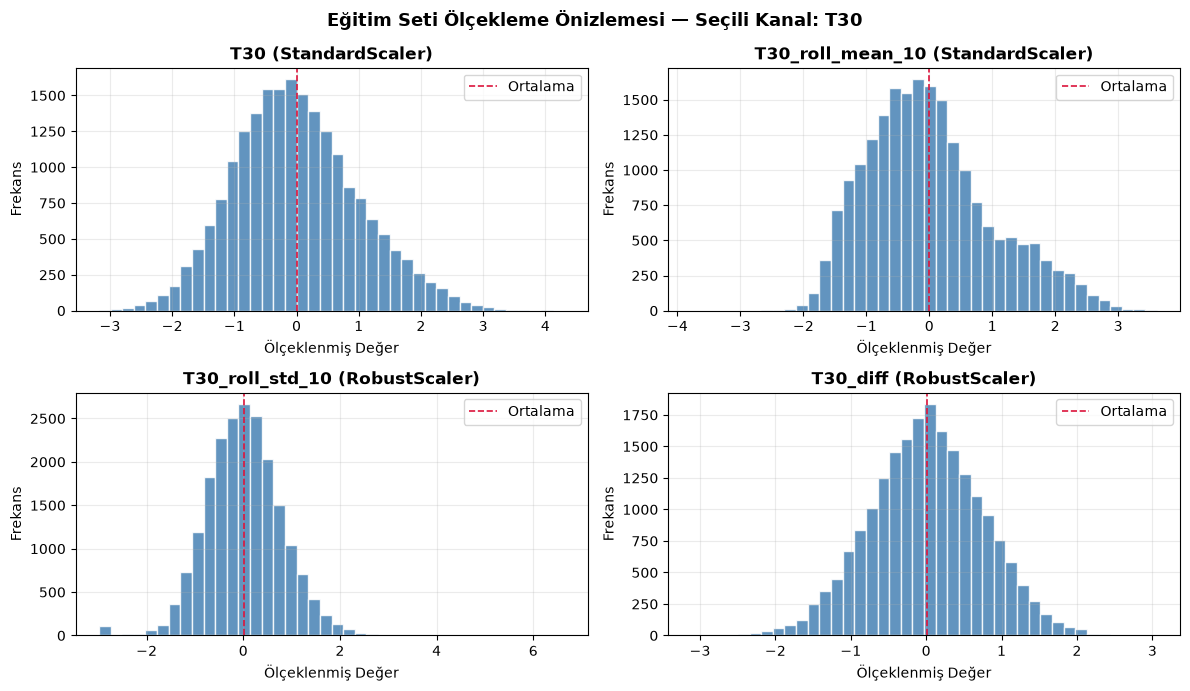

In [105]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, StandardScaler

# İncelemek istediğin sensörü/kanalı buradan kolayca değiştirebilirsin (örn: "T24", "T30", "Ps30", "Nf")
sensor = "T30"

# 1) Ölçeklenecek özellik sütunlarını belirle (unit, cycle ve hedefler hariç)
excluded_cols = {"unit", "cycle", "RUL_linear", "RUL_capped125"}
feature_cols = [
    col for col in train_fe.columns if col not in excluded_cols
]

# 2) Oynaklık/fark sütunları için RobustScaler, diğer özellikler için StandardScaler
robust_cols = [
    col for col in feature_cols if col.endswith("_diff") or "_roll_std_" in col
]
standard_cols = [col for col in feature_cols if col not in robust_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("std", StandardScaler(), standard_cols),
        ("rob", RobustScaler(), robust_cols),
    ],
    remainder="drop",
)

# 3) Veri sızıntısını önlemek ve sonraki adımları bozmamak için SADECE train_fe üzerinde fit et
# test_fe henüz dönüştürülmez; nihai dönüşüm Feature Selection ve modelleme hattında uygulanacaktır.
X_train_preview_arr = preprocessor.fit_transform(train_fe[feature_cols])

scaled_col_names = [
    name.split("__", 1)[-1] for name in preprocessor.get_feature_names_out()
]

# Dağılım kontrolü için geçici eğitim önizleme tablosu (orijinal train_fe ve test_fe korunur)
train_scaled_preview = train_fe.copy()
train_scaled_preview[scaled_col_names] = pd.DataFrame(
    X_train_preview_arr, columns=scaled_col_names, index=train_scaled_preview.index
)
train_scaled_preview = train_scaled_preview[train_fe.columns]

# 4) Bütünlük ve NaN / inf kontrolü
print("Toplam ölçeklenecek özellik sayısı:", len(feature_cols))
print("StandardScaler sütun sayısı         :", len(standard_cols))
print("RobustScaler sütun sayısı           :", len(robust_cols))
print("train_fe şekli (korundu)            :", train_fe.shape)
print("test_fe şekli (korundu)             :", test_fe.shape)
print(
    "Ölçekleme önizleme NaN / inf        :",
    int(train_scaled_preview[feature_cols].isna().sum().sum()),
    "/",
    int(np.isinf(train_scaled_preview[feature_cols]).sum().sum()),
)

# 5) Seçilen sensör ve türevleri için ölçekleme öncesi vs sonrası özet tablo (train_fe)
check_cols = [
    sensor,
    f"{sensor}_roll_mean_10",
    f"{sensor}_roll_std_10",
    f"{sensor}_diff",
]

print(f"\n[{sensor}] Ölçekleme öncesi özet (train_fe):")
print(train_fe[check_cols].agg(["mean", "std", "min", "max"]).round(3))

print(f"\n[{sensor}] Ölçekleme sonrası özet (train_scaled_preview):")
print(train_scaled_preview[check_cols].agg(["mean", "std", "min", "max"]).round(3))

# 6) Seçilen sensörün 4 özelliğinin ölçekleme sonrası dağılımı
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.ravel()

for idx, col in enumerate(check_cols):
    scaler_tag = "RobustScaler" if col in robust_cols else "StandardScaler"
    axes[idx].hist(
        train_scaled_preview[col],
        bins=40,
        color="steelblue",
        edgecolor="white",
        alpha=0.85,
    )
    axes[idx].axvline(
        train_scaled_preview[col].mean(),
        color="crimson",
        linestyle="--",
        linewidth=1.2,
        label="Ortalama",
    )
    axes[idx].set_title(f"{col} ({scaler_tag})", fontweight="bold")
    axes[idx].set_xlabel("Ölçeklenmiş Değer")
    axes[idx].set_ylabel("Frekans")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.25)

plt.suptitle(
    f"Eğitim Seti Ölçekleme Önizlemesi — Seçili Kanal: {sensor}",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

### 2.4 Özellik Seçimi ve Önemi (Feature Selection / Importance)

Özellik mühendisliği adımı sonrasında elde edilen 68 girdi özelliğinin `RUL_capped125` hedef değişkeni üzerindeki bilgilendiriciliğini değerlendirmek ve ileride kurulacak tüm modellere uygun, sadeleştirilmiş bir öznitelik kümesi oluşturmak amacıyla modele bağımsız (*model-agnostic*) özellik seçimi uygulanmıştır. Veri sızıntısını (*data leakage*) önlemek için eğitim setindeki 100 motor motor kimliği (`unit`) bazında 80 eğitim ve 20 doğrulama (*validation*) motoruna ayrılmış; düşük varyans, karşılıklı bilgi ve korelasyon hesaplamalarının tamamı yalnızca 80 motorluk eğitim alt kümesi üzerinde gerçekleştirilirken `unit` ve `cycle` sütunları zamansal bütünlük için korunmuş ancak doğrudan model özellik adayları dışında bırakılmıştır.

Uygulanan seçim sürecinde ilk olarak varyansı `0.0001` eşiğinin altında kalan 15 özellik (`op_set1`, `op_set2` ve `P15` kanalları ile bunların türevleri ve `Nf_roll_std_10`, `NRf_roll_std_10`, `BPR_roll_std_10`) elenmiştir. Kalan özellikler için `RUL_capped125` ile doğrusal ve doğrusal olmayan ilişkileri ölçmek amacıyla Karşılıklı Bilgi (*Mutual Information*) skorları hesaplanmış ve yüksek Mutual Information skoruna sahip `roll_mean_10` türevlerinin (özellikle `T50_roll_mean_10`, `W32_roll_mean_10`, `Ps30_roll_mean_10` ve `htBleed_roll_mean_10`) motor bozunma sürecini temsil etmede öne çıktığı gözlemlenmiştir[cite: 5]. Aynı kök kanala ait özellikler arasında `0.98` üzerindeki yüksek korelasyonlarda ise Mutual Information skoru daha düşük olan `Nc` (`0.2231 <= 0.2821`) ve `NRc` (`0.2231 <= 0.2868`) sütunları ayıklanırken, farklı sensör kanalları arasındaki korelasyonlar fiziksel bilgi kaybı yaşanmaması adına silinmeden incelenmiş; böylece 68 aday özellikten 51 öznitelik (`selected_features`) seçilerek modelleme aşamasına aktarılmıştır.

Train motor sayısı           : 80
Val motor sayısı             : 20
Başlangıç aday özellik       : 68
Low variance elenen (<0.0001) : 15
Kanal içi >0.98 elenen : 2
Seçilen özellik sayısı       : 51

Düşük varyanslı sütunlar: ['op_set1', 'op_set2', 'P15', 'op_set1_roll_mean_10', 'op_set1_roll_std_10', 'op_set1_diff', 'op_set2_roll_mean_10', 'op_set2_roll_std_10', 'op_set2_diff', 'P15_roll_mean_10', 'P15_roll_std_10', 'P15_diff', 'Nf_roll_std_10', 'NRf_roll_std_10', 'BPR_roll_std_10']

Kanal içi tekrar nedeniyle elenen sütunlar ve gerekçeleri:
  - Nc: Nc_roll_mean_10 ile r=0.9840 (MI: 0.2231 <= 0.2821)
  - NRc: NRc_roll_mean_10 ile r=0.9873 (MI: 0.2231 <= 0.2868)

Farklı kanallar arası yüksek korelasyon (>0.9, silinmedi) sayısı: 61
  - Nc_roll_mean_10 <-> NRc_roll_mean_10: |r| = 0.9882
  - NRc <-> Nc_roll_mean_10: |r| = 0.9777
  - Ps30_roll_mean_10 <-> phi_roll_mean_10: |r| = 0.9759
  - T50_roll_mean_10 <-> Ps30_roll_mean_10: |r| = 0.9749
  - Nf_roll_mean_10 <-> NRf_roll_mean_10: |r| = 0

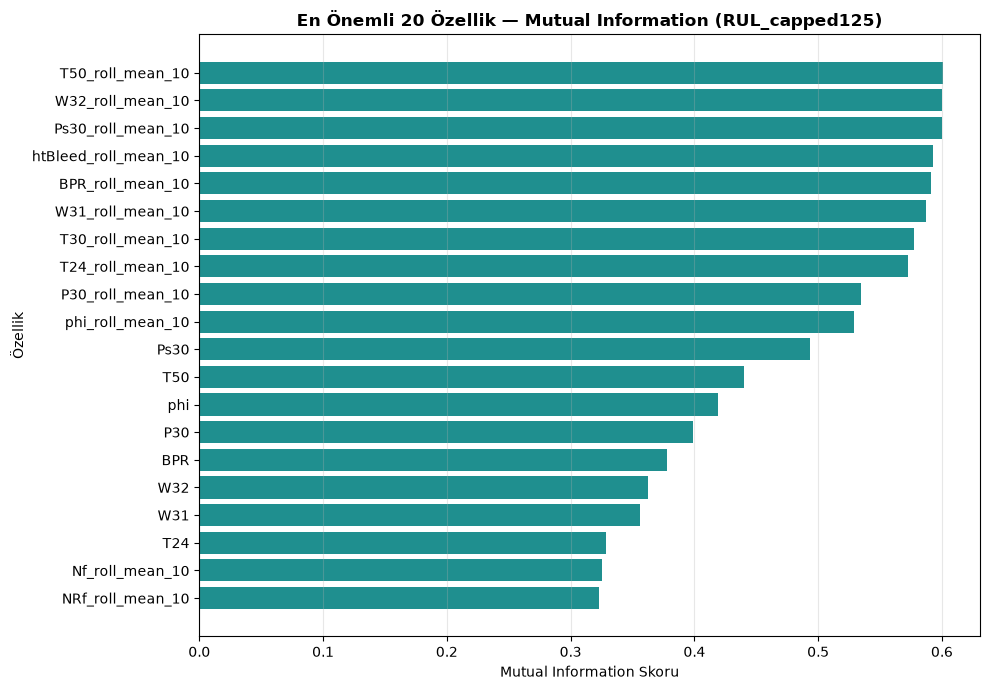

In [106]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import VarianceThreshold, mutual_info_regression
from sklearn.model_selection import GroupShuffleSplit

# --- 0) Önceki FS ara değişkenlerini temizle ---
for _v in [
    "fs_df",
    "selected_features",
    "dropped_redundant",
    "low_var_cols",
    "vt",
    "mi_scores",
    "corr_matrix",
]:
  if _v in globals():
    del globals()[_v]

# --- Ayarlanabilir parametreler ---
TARGET_COL = "RUL_capped125"
VAL_SIZE = 0.20
VAR_THRESHOLD = 1e-4
SAME_CHANNEL_CORR_THRESHOLD = 0.98
CROSS_CHANNEL_INSPECT_THRESHOLD = 0.90
TOP_N_PLOT = 20
RANDOM_STATE = 42


def get_base_channel(col_name: str) -> str:
  """Özellik adından kök sensör/operasyonel kanal adını çıkarır."""
  for suffix in ["_roll_mean_10", "_roll_std_10", "_diff"]:
    if col_name.endswith(suffix):
      return col_name[: -len(suffix)]
  return col_name


# --- 1) Motor (unit) bazında Train / Validation ayrımı ---
# unit ve cycle sütunları tablolarda korunur, model girdi adaylarından çıkarılır
gss = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss.split(train_fe, groups=train_fe["unit"]))

train_fs_split = train_fe.iloc[train_idx].copy()
val_fs_split = train_fe.iloc[val_idx].copy()

assert set(train_fs_split["unit"]).isdisjoint(
    set(val_fs_split["unit"])
), "Veri sızıntısı: Aynı motor hem train hem val setinde!"

excluded_cols = {"unit", "cycle", "RUL_linear", "RUL_capped125"}
candidate_cols = [
    col for col in train_fs_split.columns if col not in excluded_cols
]

X_tr = train_fs_split[candidate_cols]
y_tr = train_fs_split[TARGET_COL]

# --- 2) Low Variance Filter (yalnızca train_fs_split üzerinde) ---
vt = VarianceThreshold(threshold=VAR_THRESHOLD)
vt.fit(X_tr)
var_mask = vt.get_support()

low_var_cols = [
    col for col, keep in zip(candidate_cols, var_mask) if not keep
]
active_cols = [col for col, keep in zip(candidate_cols, var_mask) if keep]
X_tr_active = X_tr[active_cols]

# --- 3) Mutual Information (yalnızca train_fs_split üzerinde) ---
mi_scores = mutual_info_regression(
    X_tr_active, y_tr, random_state=RANDOM_STATE
)

fs_df = (
    pd.DataFrame({
        "feature": active_cols,
        "base_channel": [get_base_channel(c) for c in active_cols],
        "mi_score": mi_scores,
    })
    .sort_values("mi_score", ascending=False)
    .reset_index(drop=True)
)

# --- 4) Aynı kanalda |r| > 0.98 ise MI skoru düşük olanı ele ---
corr_matrix = X_tr_active.corr().abs()
mi_lookup = dict(zip(fs_df["feature"], fs_df["mi_score"]))

selected_features = []
dropped_redundant = []
drop_reasons = {}

# Yüksek MI'dan düşük MI'a doğru sıralı ilerleyerek daha bilgilendirici olanı önceliklendir
for _, row in fs_df.iterrows():
  feat = row["feature"]
  feat_ch = row["base_channel"]
  feat_mi = row["mi_score"]

  conflicting_kept = [
      kept
      for kept in selected_features
      if (get_base_channel(kept) == feat_ch)
      and (corr_matrix.loc[feat, kept] > SAME_CHANNEL_CORR_THRESHOLD)
  ]

  if conflicting_kept:
    # Seçilmiş olanlardan en yüksek korelasyonlu/en yüksek MI'lı olanla kıyasla
    best_kept = max(conflicting_kept, key=lambda k: mi_lookup[k])
    if feat_mi <= mi_lookup[best_kept]:
      dropped_redundant.append(feat)
      drop_reasons[feat] = (
          f"{best_kept} ile r={corr_matrix.loc[feat, best_kept]:.4f} "
          f"(MI: {feat_mi:.4f} <= {mi_lookup[best_kept]:.4f})"
      )
    else:
      # Teorik olarak yüksek MI'lı önce geldiği için nadiren çalışır; yine de güvenli
      selected_features.remove(best_kept)
      dropped_redundant.append(best_kept)
      drop_reasons[best_kept] = (
          f"{feat} ile r={corr_matrix.loc[feat, best_kept]:.4f} "
          f"(MI: {mi_lookup[best_kept]:.4f} <= {feat_mi:.4f})"
      )
      selected_features.append(feat)
  else:
    selected_features.append(feat)

fs_df["status"] = np.where(
    fs_df["feature"].isin(selected_features),
    "Seçildi",
    "Elenen (Kanal İçi Tekrar)",
)

# --- 5) Farklı sensörler/kanallar arası yüksek korelasyonu incele (silmeden raporla) ---
cross_high_corr = []
cols_list = X_tr_active.columns.tolist()
for i in range(len(cols_list)):
  for j in range(i + 1, len(cols_list)):
    c1, c2 = cols_list[i], cols_list[j]
    if get_base_channel(c1) != get_base_channel(c2):
      r_val = corr_matrix.loc[c1, c2]
      if r_val > CROSS_CHANNEL_INSPECT_THRESHOLD:
        cross_high_corr.append((c1, c2, round(float(r_val), 4)))

cross_high_corr.sort(key=lambda x: x[2], reverse=True)

# --- Özet Çıktılar ---
print(f"Train motor sayısı           : {train_fs_split['unit'].nunique()}")
print(f"Val motor sayısı             : {val_fs_split['unit'].nunique()}")
print(f"Başlangıç aday özellik       : {len(candidate_cols)}")
print(f"Low variance elenen (<{VAR_THRESHOLD}) : {len(low_var_cols)}")
print(
    f"Kanal içi >{SAME_CHANNEL_CORR_THRESHOLD} elenen :"
    f" {len(dropped_redundant)}"
)
print(f"Seçilen özellik sayısı       : {len(selected_features)}")

if low_var_cols:
  print("\nDüşük varyanslı sütunlar:", low_var_cols)

if dropped_redundant:
  print("\nKanal içi tekrar nedeniyle elenen sütunlar ve gerekçeleri:")
  for k, v in drop_reasons.items():
    print(f"  - {k}: {v}")

print(
    f"\nFarklı kanallar arası yüksek korelasyon (>{CROSS_CHANNEL_INSPECT_THRESHOLD},"
    f" silinmedi) sayısı: {len(cross_high_corr)}"
)
for c1, c2, r_val in cross_high_corr[:10]:
  print(f"  - {c1} <-> {c2}: |r| = {r_val}")

print("\nEn önemli ilk 15 özellik:")
print(
    fs_df[["feature", "base_channel", "mi_score", "status"]]
    .head(15)
    .round(4)
    .to_string(index=False)
)

# --- Görselleştirme ---
top_plot_df = fs_df.head(TOP_N_PLOT).iloc[::-1]
bar_colors = [
    "teal" if st == "Seçildi" else "coral" for st in top_plot_df["status"]
]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    top_plot_df["feature"],
    top_plot_df["mi_score"],
    color=bar_colors,
    alpha=0.88,
)
ax.set_title(
    f"En Önemli {TOP_N_PLOT} Özellik — Mutual Information ({TARGET_COL})",
    fontweight="bold",
)
ax.set_xlabel("Mutual Information Skoru")
ax.set_ylabel("Özellik")
ax.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()